In [ ]:
!pip install -q pennylane tensorflow-hub scikit-learn matplotlib pillow tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 51.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 88.3 MB/s eta 0:00:00


In [ ]:
import os
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_hub as hub
import torch
import torch.nn as nn
import pennylane as qml

from PIL import Image
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow: 2.21.0
PyTorch: 2.11.0+cu130
GPU available: True


In [ ]:
uploaded = files.upload()

zip_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload your dataset ZIP files.")

print("Uploaded ZIP files:")
for filename in zip_files:
    print(filename)

Saving archive(1).zip to archive(1).zip
Uploaded ZIP files:
archive(1).zip


In [ ]:
uploaded = files.upload()

zip_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload your dataset ZIP files.")

print("Uploaded ZIP files:")
for filename in zip_files:
    print(filename)

Saving archive(1).zip to archive(1) (1).zip
Saving archive(2).zip to archive(2).zip
Uploaded ZIP files:
archive(1) (1).zip
archive(2).zip


In [ ]:
EXTRACT_BASE = "/content/datasets"
os.makedirs(EXTRACT_BASE, exist_ok=True)

for filename in zip_files:
    dataset_name = os.path.splitext(os.path.basename(filename))[0]
    destination = os.path.join(EXTRACT_BASE, dataset_name)
    os.makedirs(destination, exist_ok=True)

    with zipfile.ZipFile(filename, "r") as archive:
        archive.extractall(destination)

    print(f"Extracted: {filename} -> {destination}")

Extracted: archive(1) (1).zip -> /content/datasets/archive(1) (1)
Extracted: archive(2).zip -> /content/datasets/archive(2)


In [ ]:
def find_folder(folder_name, search_root="/content"):
    for root, dirs, files_list in os.walk(search_root):
        if os.path.basename(root).lower() == folder_name.lower():
            return root
    return None

CARLA_ROOT = find_folder("traffic_light_data")
LISA_ROOT = find_folder("cropped_lisa_1")

print("CARLA_ROOT:", CARLA_ROOT)
print("LISA_ROOT :", LISA_ROOT)

if CARLA_ROOT is None:
    print("CARLA folder not found. Check the extracted folder names.")

if LISA_ROOT is None:
    print("Cropped LISA folder not found. Check the extracted folder names.")

CARLA_ROOT: /content/datasets/archive(2)/traffic_light_data
LISA_ROOT : /content/datasets/archive(1) (1)/cropped_lisa_1


In [ ]:
import os

print("Folders inside /content/datasets:\n")

for root, dirs, files in os.walk("/content/datasets"):
    level = root.replace("/content/datasets", "").count(os.sep)
    if level <= 4:
        print("  " * level + os.path.basename(root) + "/")

print("\nZIP files inside /content:")
for name in os.listdir("/content"):
    if name.lower().endswith(".zip"):
        print(name)

Folders inside /content/datasets:

datasets/
  archive(2)/
    traffic_light_data/
      val/
        red/
        green/
        yellow/
        back/
      train/
        red/
        green/
        yellow/
        back/
  archive(1) (1)/
    cropped_lisa_1/
      train_1/
        stopLeft/
        goForward/
        warning/
        goLeft/
        warningLeft/
        stop/
        go/
      val_1/
        stopLeft/
        goForward/
        warning/
        goLeft/
        warningLeft/
        stop/
        go/

ZIP files inside /content:
archive(2).zip
archive(1) (1).zip
archive(1).zip


In [ ]:
import os
import zipfile

LISA_ZIP = "/content/archive(1).zip"
LISA_EXTRACT = "/content/datasets/lisa_extracted"

os.makedirs(LISA_EXTRACT, exist_ok=True)

with zipfile.ZipFile(LISA_ZIP, "r") as z:
    z.extractall(LISA_EXTRACT)

print("Extraction completed.")

for root, dirs, files in os.walk(LISA_EXTRACT):
    level = root.replace(LISA_EXTRACT, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

Extraction completed.
lisa_extracted/
  cropped_lisa_1/
    train_1/
      stopLeft/
      goForward/
      warning/
      goLeft/
      warningLeft/
      stop/
      go/
    val_1/
      stopLeft/
      goForward/
      warning/
      goLeft/
      warningLeft/
      stop/
      go/


In [ ]:
import os

CARLA_ROOT = "/content/datasets/archive(2)/traffic_light_data"

LISA_ROOT = None

for root, dirs, files in os.walk("/content/datasets/lisa_extracted"):
    if os.path.basename(root).lower() == "cropped_lisa_1":
        LISA_ROOT = root
        break

print("CARLA_ROOT:", CARLA_ROOT)
print("LISA_ROOT :", LISA_ROOT)

assert os.path.isdir(CARLA_ROOT), "CARLA folder not found."
assert LISA_ROOT is not None, (
    "Cropped LISA not found. Check the ZIP contents from Cell 1."
)

CARLA_ROOT: /content/datasets/archive(2)/traffic_light_data
LISA_ROOT : /content/datasets/lisa_extracted/cropped_lisa_1


In [ ]:
import os

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def show_dataset(root, name):
    print(f"\n{'=' * 45}")
    print(name)
    print(f"{'=' * 45}")

    if not os.path.isdir(root):
        print("ERROR: Dataset path does not exist.")
        return

    for split in os.listdir(root):
        split_path = os.path.join(root, split)

        if not os.path.isdir(split_path):
            continue

        print(f"\n{split}/")

        for class_name in sorted(os.listdir(split_path)):
            class_path = os.path.join(split_path, class_name)

            if not os.path.isdir(class_path):
                continue

            count = sum(
                1 for filename in os.listdir(class_path)
                if os.path.splitext(filename)[1].lower()
                in IMAGE_EXTENSIONS
            )

            print(f"  {class_name}: {count} images")


show_dataset(CARLA_ROOT, "CARLA DATASET")
show_dataset(LISA_ROOT, "CROPPED LISA DATASET")


CARLA DATASET

val/
  back: 100 images
  green: 100 images
  red: 100 images
  yellow: 83 images

train/
  back: 517 images
  green: 559 images
  red: 564 images
  yellow: 503 images

CROPPED LISA DATASET

train_1/
  go: 12840 images
  goForward: 184 images
  goLeft: 1030 images
  stop: 14865 images
  stopLeft: 2845 images
  warningLeft: 48 images

val_1/
  go: 1372 images
  goForward: 21 images
  goLeft: 109 images
  stop: 1777 images
  stopLeft: 345 images
  warningLeft: 5 images


In [ ]:
MAX_PER_CLASS = None

CLASS_NAMES = ["red", "yellow", "green"]
CLASS_TO_ID = {"red": 0, "yellow": 1, "green": 2}

LISA_CLASS_MAP = {
    "stop": 0,
    "warning": 1,
    "go": 2
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

In [ ]:
import os
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_TO_ID = {"red": 0, "yellow": 1, "green": 2}

LISA_CLASS_MAP = {
    "stop": 0,
    "warning": 1,
    "go": 2
}


def image_to_angles(image):
    image = Image.fromarray(
        np.asarray(image, dtype=np.uint8)
    ).resize((2, 2), Image.Resampling.LANCZOS).convert("L")

    pixels = np.asarray(image, dtype=np.float32)
    return (pixels * np.pi / 255.0).flatten().astype(np.float32)


def find_class_dirs(root, accepted_classes):
    matches = []

    for current_root, dirs, files in os.walk(root):
        if os.path.basename(current_root).lower() in accepted_classes:
            matches.append(current_root)

    return matches


def prepare_carla(root, max_per_class=None):
    X, y = [], []
    counts = {name: 0 for name in CLASS_TO_ID}

    class_dirs = find_class_dirs(root, set(CLASS_TO_ID))

    for folder in class_dirs:
        class_name = os.path.basename(folder).lower()
        label = CLASS_TO_ID[class_name]

        paths = sorted([
            os.path.join(folder, filename)
            for filename in os.listdir(folder)
            if os.path.splitext(filename)[1].lower() in IMAGE_EXTENSIONS
        ])

        if max_per_class is not None:
            paths = paths[:max_per_class]

        for path in tqdm(paths, desc=f"CARLA {class_name}"):
            try:
                with Image.open(path) as im:
                    original = np.asarray(im.convert("RGB"))

                # Requires your earlier TensorFlow detector function.
                crop, _ = detect_and_crop(original)

                if crop is None:
                    continue

                X.append(image_to_angles(crop))
                y.append(label)
                counts[class_name] += 1

            except Exception as e:
                print(f"Skipped {path}: {e}")

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int64),
        counts
    )


def prepare_lisa(root, max_per_class=None):
    X, y = [], []
    counts = {name: 0 for name in LISA_CLASS_MAP}

    class_dirs = find_class_dirs(root, set(LISA_CLASS_MAP))

    for folder in class_dirs:
        class_name = os.path.basename(folder).lower()
        label = LISA_CLASS_MAP[class_name]

        paths = sorted([
            os.path.join(folder, filename)
            for filename in os.listdir(folder)
            if os.path.splitext(filename)[1].lower() in IMAGE_EXTENSIONS
        ])

        if max_per_class is not None:
            paths = paths[:max_per_class]

        for path in tqdm(paths, desc=f"LISA {class_name}"):
            try:
                with Image.open(path) as im:
                    image = im.convert("RGB")
                    X.append(image_to_angles(image))
                    y.append(label)
                    counts[class_name] += 1

            except Exception as e:
                print(f"Skipped {path}: {e}")

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int64),
        counts
    )


print("Preprocessing functions defined successfully.")

Preprocessing functions defined successfully.


In [ ]:
import os

for split in ["train", "val"]:
    split_path = os.path.join(CARLA_ROOT, split)
    print(f"\n{split_path}")

    if not os.path.isdir(split_path):
        print("Split folder not found")
        continue

    for cls in sorted(os.listdir(split_path)):
        cls_path = os.path.join(split_path, cls)

        if os.path.isdir(cls_path):
            files = [
                f for f in os.listdir(cls_path)
                if os.path.splitext(f)[1].lower()
                in IMAGE_EXTENSIONS
            ]
            print(f"{cls}: {len(files)} images")
            if files:
                print("  Example:", files[0])


/content/datasets/archive(2)/traffic_light_data/train
back: 517 images
  Example: back_305.png
green: 559 images
  Example: green_249.jpg
red: 564 images
  Example: red_136.png
yellow: 503 images
  Example: yellow_308.jpg

/content/datasets/archive(2)/traffic_light_data/val
back: 100 images
  Example: back_25.png
green: 100 images
  Example: green_14.jpg
red: 100 images
  Example: red_7.png
yellow: 83 images
  Example: yellow_83.jpg


In [ ]:
import os
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_TO_ID = {"red": 0, "yellow": 1, "green": 2}

def prepare_carla(root, max_per_class=None):
    X, y = [], []
    counts = {name: 0 for name in CLASS_TO_ID}

    for split in ["train", "val"]:
        split_path = os.path.join(root, split)

        if not os.path.isdir(split_path):
            print("Skipping missing split:", split_path)
            continue

        for class_name, label in CLASS_TO_ID.items():
            class_path = os.path.join(split_path, class_name)

            if not os.path.isdir(class_path):
                continue

            files = sorted([
                f for f in os.listdir(class_path)
                if os.path.splitext(f)[1].lower() in IMAGE_EXTENSIONS
            ])

            if max_per_class is not None:
                files = files[:max_per_class]

            for filename in tqdm(files, desc=f"{split}/{class_name}"):
                path = os.path.join(class_path, filename)

                try:
                    with Image.open(path) as im:
                        image = im.convert("L").resize(
                            (2, 2), Image.Resampling.LANCZOS
                        )
                        pixels = np.asarray(image, dtype=np.float32)

                    angles = (pixels * np.pi / 255.0).flatten()

                    X.append(angles.astype(np.float32))
                    y.append(label)
                    counts[class_name] += 1

                except Exception as e:
                    print("Skipped:", path, e)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int64),
        counts
    )

In [ ]:
X_carla, y_carla, carla_counts = prepare_carla(
    CARLA_ROOT,
    max_per_class=None
)

print("CARLA feature shape:", X_carla.shape)
print("CARLA label shape:", y_carla.shape)
print("CARLA class counts:", carla_counts)

train/red:   0%|          | 0/564 [00:00<?, ?it/s]

train/yellow:   0%|          | 0/503 [00:00<?, ?it/s]

train/green:   0%|          | 0/559 [00:00<?, ?it/s]

val/red:   0%|          | 0/100 [00:00<?, ?it/s]

val/yellow:   0%|          | 0/83 [00:00<?, ?it/s]

val/green:   0%|          | 0/100 [00:00<?, ?it/s]

CARLA feature shape: (1909, 4)
CARLA label shape: (1909,)
CARLA class counts: {'red': 664, 'yellow': 586, 'green': 659}


In [ ]:

import numpy as np
from pathlib import Path
from PIL import Image

CARLA_ROOT = Path("/content/datasets/archive(2)/traffic_light_data")
LISA_ROOT = Path("/content/datasets/lisa_extracted/cropped_lisa_1")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def process_dataset(root, train_names, val_names, name):
    def find_split(names):
        for folder in names:
            path = root / folder
            if path.is_dir():
                return path
        raise FileNotFoundError(
            f"{name}: Could not find {names} inside {root}. "
            "Check your extracted dataset paths."
        )

    train_dir = find_split(train_names)
    val_dir = find_split(val_names)

    train_classes = sorted(
        p.name for p in train_dir.iterdir() if p.is_dir()
    )
    val_classes = sorted(
        p.name for p in val_dir.iterdir() if p.is_dir()
    )

    if train_classes != val_classes:
        raise ValueError(
            f"{name}: Train and validation class folders differ.\n"
            f"Train: {train_classes}\nValidation: {val_classes}"
        )

    class_to_idx = {c: i for i, c in enumerate(train_classes)}

    def load_split(folder):
        X, y = [], []
        for cls in train_classes:
            class_dir = folder / cls
            for path in class_dir.rglob("*"):
                if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue
                try:
                    with Image.open(path) as img:
                        img = img.convert("RGB").resize(
                            (2, 2), Image.Resampling.LANCZOS
                        ).convert("L")
                        pixels = np.asarray(img, dtype=np.float32).reshape(4)
                    X.append((pixels / 255.0) * np.pi)
                    y.append(class_to_idx[cls])
                except Exception as e:
                    print("Skipped:", path, e)

        return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.int64)

    X_train, y_train = load_split(train_dir)
    X_val, y_val = load_split(val_dir)

    if len(X_train) == 0 or len(X_val) == 0:
        raise ValueError(f"{name}: no images found in train or validation.")

    data = {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "classes": train_classes,
        "class_to_idx": class_to_idx
    }

    print(f"\n{name}")
    print("Classes:", train_classes)
    print("Train:", X_train.shape, y_train.shape)
    print("Validation:", X_val.shape, y_val.shape)
    return data

carla_data = process_dataset(
    CARLA_ROOT, ["train"], ["val", "valid", "validation"], "CARLA"
)

lisa_data = process_dataset(
    LISA_ROOT, ["train_1", "train"],
    ["val_1", "val", "valid", "validation"], "Cropped LISA"
)

print("\nBoth datasets are ready.")



CARLA
Classes: ['back', 'green', 'red', 'yellow']
Train: (2143, 4) (2143,)
Validation: (383, 4) (383,)

Cropped LISA
Classes: ['go', 'goForward', 'goLeft', 'stop', 'stopLeft', 'warning', 'warningLeft']
Train: (32797, 4) (32797,)
Validation: (3737, 4) (3737,)

Both datasets are ready.


In [ ]:

X_carla = carla_data["X_train"]
y_carla = carla_data["y_train"]
X_lisa = lisa_data["X_train"]
y_lisa = lisa_data["y_train"]

print("CARLA:", X_carla.shape, y_carla.shape)
print("LISA:", X_lisa.shape, y_lisa.shape)


CARLA: (2143, 4) (2143,)
LISA: (32797, 4) (32797,)


In [ ]:
from PIL import Image

path = "/content/datasets/archive(2)/traffic_light_data/val/red/red_88.png"

img = Image.open(path)

print("Original size:", img.size)
print("Image mode:", img.mode)

img.save("/content/original_check.png")

Original size: (4, 19)
Image mode: RGB


In [ ]:
from PIL import Image
import os
from collections import Counter

sizes = Counter()
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for root, dirs, files in os.walk(CARLA_ROOT):
    for file in files:
        if os.path.splitext(file)[1].lower() in extensions:
            path = os.path.join(root, file)

            try:
                with Image.open(path) as img:
                    sizes[img.size] += 1
            except Exception:
                pass

print("Most common original image sizes:")
for size, count in sizes.most_common(10):
    print(f"{size}: {count} images")

Most common original image sizes:
(10, 34): 47 images
(10, 31): 43 images
(13, 52): 40 images
(16, 58): 38 images
(10, 28): 38 images
(32, 62): 35 images
(13, 40): 32 images
(7, 28): 31 images
(7, 34): 30 images
(13, 37): 30 images


In [ ]:
from PIL import Image
import os
import numpy as np

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
widths, heights = [], []

for root, dirs, files in os.walk(CARLA_ROOT):
    for filename in files:
        if os.path.splitext(filename)[1].lower() not in extensions:
            continue

        path = os.path.join(root, filename)

        try:
            with Image.open(path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
        except Exception:
            pass

print("Total images:", len(widths))
print("Minimum width:", min(widths))
print("Minimum height:", min(heights))
print("Maximum width:", max(widths))
print("Maximum height:", max(heights))
print("Average width:", round(np.mean(widths), 2))
print("Average height:", round(np.mean(heights), 2))
print("Images smaller than 20 x 20:",
      sum(w < 20 and h < 20 for w, h in zip(widths, heights)))

Total images: 2526
Minimum width: 4
Minimum height: 8
Maximum width: 455
Maximum height: 660
Average width: 29.88
Average height: 76.59
Images smaller than 20 x 20: 127


In [ ]:
from PIL import Image
from collections import defaultdict
import os
import numpy as np

sizes_by_class = defaultdict(list)
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val"]:
    for cls in ["red", "yellow", "green", "back"]:
        folder = os.path.join(CARLA_ROOT, split, cls)

        if not os.path.isdir(folder):
            continue

        for filename in os.listdir(folder):
            if os.path.splitext(filename)[1].lower() not in extensions:
                continue

            try:
                with Image.open(os.path.join(folder, filename)) as img:
                    sizes_by_class[f"{split}/{cls}"].append(img.size)
            except Exception:
                pass

for name, sizes in sorted(sizes_by_class.items()):
    areas = [w * h for w, h in sizes]
    print(
        f"{name}: {len(sizes)} images | "
        f"minimum={min(areas)} pixels | "
        f"median={np.median(areas):.0f} pixels"
    )

train/back: 517 images | minimum=40 pixels | median=481 pixels
train/green: 559 images | minimum=64 pixels | median=1540 pixels
train/red: 564 images | minimum=52 pixels | median=676 pixels
train/yellow: 503 images | minimum=40 pixels | median=1482 pixels
val/back: 100 images | minimum=76 pixels | median=520 pixels
val/green: 100 images | minimum=76 pixels | median=2092 pixels
val/red: 100 images | minimum=52 pixels | median=1360 pixels
val/yellow: 83 images | minimum=64 pixels | median=1984 pixels


In [ ]:
!pip -q install tensorflow-hub

import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

print("TensorFlow version:", tf.__version__)
print("TensorFlow Hub imported successfully.")

TensorFlow version: 2.21.0
TensorFlow Hub imported successfully.


In [ ]:
MODEL_URL = "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"

detector = hub.load(MODEL_URL)

print("TensorFlow object detector loaded successfully.")

TensorFlow object detector loaded successfully.


Image path: /content/datasets/archive(2)/traffic_light_data/train/yellow/yellow_265.jpg
Original image shape: (604, 455, 3)


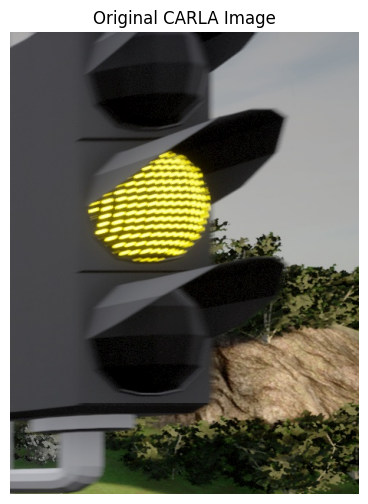

In [ ]:
CARLA_ROOT = "/content/datasets/archive(2)/traffic_light_data"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

candidate = None
largest_area = 0

for split in ["train", "val"]:
    for cls in ["red", "yellow", "green", "back"]:
        folder = os.path.join(CARLA_ROOT, split, cls)

        if not os.path.isdir(folder):
            continue

        for filename in os.listdir(folder):
            if os.path.splitext(filename)[1].lower() not in IMAGE_EXTENSIONS:
                continue

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as im:
                    width, height = im.size

                if width * height > largest_area:
                    largest_area = width * height
                    candidate = path

            except Exception:
                pass

if candidate is None:
    raise FileNotFoundError("No CARLA images found.")

with Image.open(candidate) as im:
    test_image = np.array(im.convert("RGB"))

print("Image path:", candidate)
print("Original image shape:", test_image.shape)

plt.figure(figsize=(6, 6))
plt.imshow(test_image)
plt.title("Original CARLA Image")
plt.axis("off")
plt.show()

In [ ]:
def detect_traffic_light(image, threshold=0.30):
    image_tensor = tf.convert_to_tensor(image, dtype=tf.uint8)
    image_tensor = tf.expand_dims(image_tensor, axis=0)

    detections = detector(image_tensor)

    boxes = detections["detection_boxes"][0].numpy()
    classes = detections["detection_classes"][0].numpy().astype(int)
    scores = detections["detection_scores"][0].numpy()

    height, width = image.shape[:2]
    found = []

    for box, cls, score in zip(boxes, classes, scores):
        if cls == 10 and score >= threshold:
            ymin, xmin, ymax, xmax = box

            x1 = max(0, int(xmin * width))
            y1 = max(0, int(ymin * height))
            x2 = min(width, int(xmax * width))
            y2 = min(height, int(ymax * height))

            if x2 > x1 and y2 > y1:
                crop = image[y1:y2, x1:x2]
                found.append({
                    "crop": crop,
                    "box": (x1, y1, x2, y2),
                    "score": float(score)
                })

    return found


detections = detect_traffic_light(test_image)

print("Traffic lights detected:", len(detections))

for i, item in enumerate(detections):
    print(f"Detection {i + 1}: confidence={item['score']:.3f}")

Traffic lights detected: 5
Detection 1: confidence=0.686
Detection 2: confidence=0.458
Detection 3: confidence=0.439
Detection 4: confidence=0.364
Detection 5: confidence=0.330


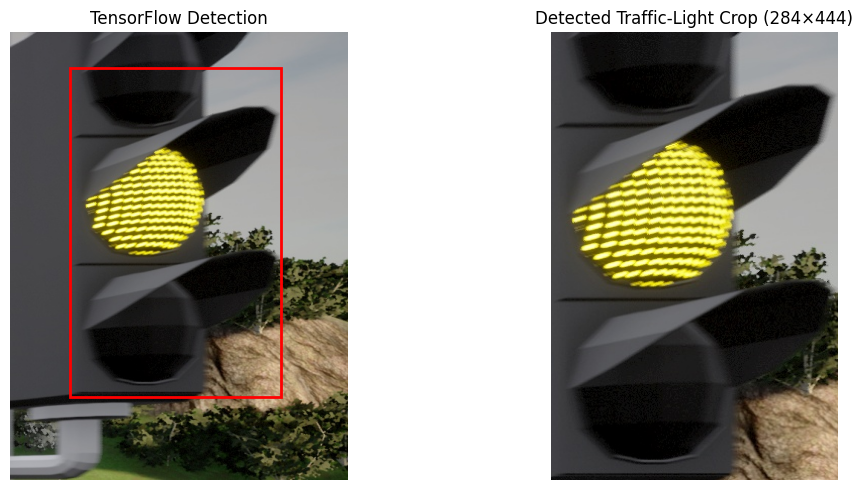

Detection succeeded.


In [ ]:
if detections:
    best = max(detections, key=lambda item: item["score"])
    x1, y1, x2, y2 = best["box"]
    crop = best["crop"]

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(test_image)
    plt.gca().add_patch(
        plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="red", linewidth=2
        )
    )
    plt.title("TensorFlow Detection")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(crop)
    plt.title(f"Detected Traffic-Light Crop ({crop.shape[1]}×{crop.shape[0]})")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Detection succeeded.")
else:
    print("No traffic light detected.")
    print("Try another larger original image or inspect the dataset format.")

Total images found: 2526
Image 1: green_155.jpg — Detection succeeded
Image 2: yellow_265.jpg — Detection succeeded
Image 3: yellow_60.jpg — Detection succeeded
Image 4: green_158.jpg — Detection succeeded


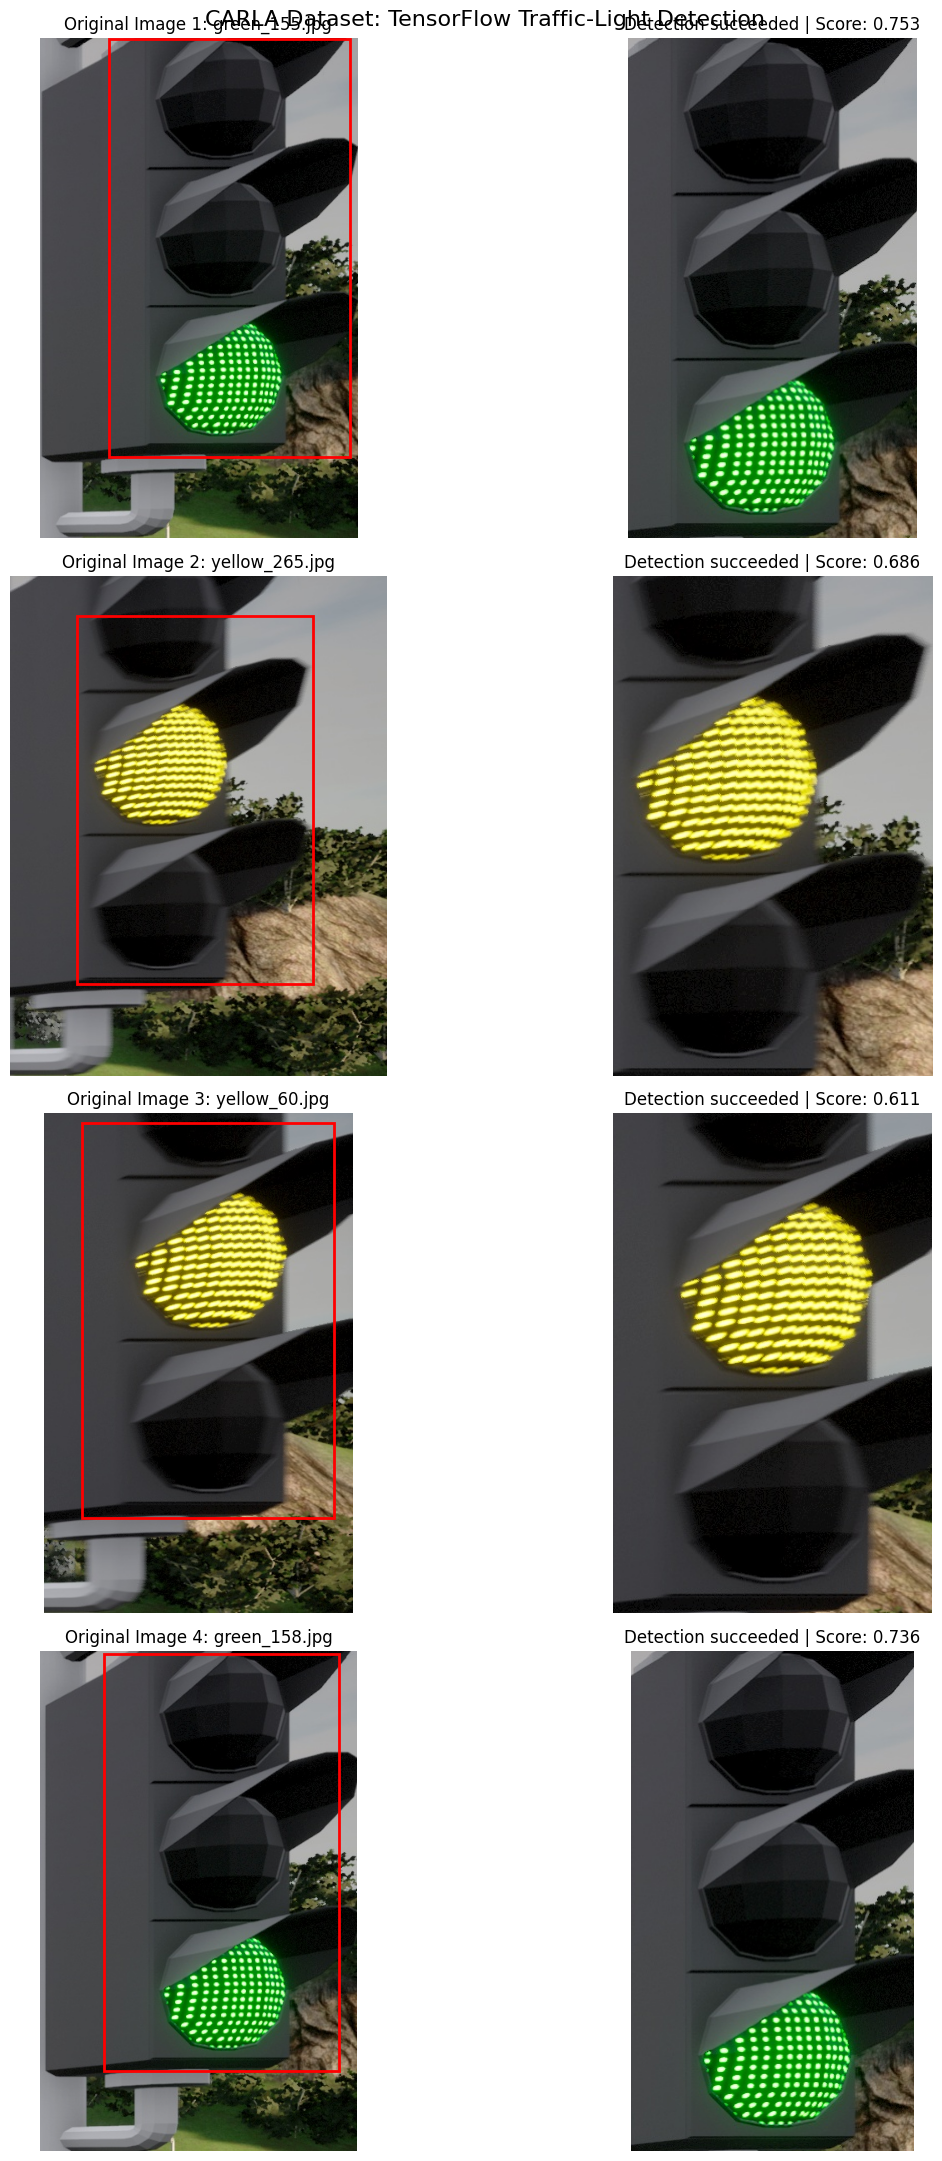

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
import random

# --------------------------------------------------
# 1. CARLA DATASET PATH
# --------------------------------------------------
carla_root = Path(CARLA_ROOT)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = [
    p for p in carla_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_paths))

if len(image_paths) < 4:
    raise ValueError(
        "Fewer than 4 images found. Check CARLA_ROOT: "
        + str(CARLA_ROOT)
    )

# --------------------------------------------------
# 2. SELECT FOUR LARGE IMAGES
# --------------------------------------------------
candidates = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            width, height = img.size

        if width >= 20 and height >= 20:
            candidates.append((path, width * height))

    except Exception as error:
        print("Skipping unreadable image:", path.name)

# Fall back to all readable images if necessary
if len(candidates) < 4:
    candidates = []

    for path in image_paths:
        try:
            with Image.open(path) as img:
                candidates.append((path, img.width * img.height))
        except Exception:
            pass

if len(candidates) < 4:
    raise ValueError("Could not find four readable images.")

# Select randomly from up to 20 of the largest images
candidates.sort(key=lambda item: item[1], reverse=True)
top_candidates = candidates[:min(20, len(candidates))]
selected_images = random.sample(top_candidates, 4)

# --------------------------------------------------
# 3. DETECT AND VISUALIZE FOUR IMAGES
# --------------------------------------------------
fig, axes = plt.subplots(4, 2, figsize=(14, 22))

for i, (path, _) in enumerate(selected_images):

    # Load as NumPy array (required by the detector)
    with Image.open(path) as img:
        test_image = np.array(img.convert("RGB"))

    # Run the existing TensorFlow detection function
    detections = detect_traffic_light(test_image)

    # Left column: original image
    axes[i, 0].imshow(test_image)
    axes[i, 0].set_title(f"Original Image {i + 1}: {path.name}")

    # Right column: detection result
    if detections:
        best = max(detections, key=lambda item: item["score"])

        x1, y1, x2, y2 = best["box"]
        crop = best["crop"]

        # Draw bounding box on original image
        rectangle = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        )
        axes[i, 0].add_patch(rectangle)

        # Display detected crop
        axes[i, 1].imshow(crop)
        axes[i, 1].set_title(
            f"Detection succeeded | Score: {best['score']:.3f}"
        )

        print(
            f"Image {i + 1}: {path.name} — "
            f"Detection succeeded"
        )

    else:
        # If no detection, show the original image
        axes[i, 1].imshow(test_image)
        axes[i, 1].set_title("No traffic light detected")

        print(
            f"Image {i + 1}: {path.name} — "
            f"No traffic light detected"
        )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.suptitle(
    "CARLA Dataset: TensorFlow Traffic-Light Detection",
    fontsize=16
)
plt.tight_layout()
plt.show()


Detected crop shape: (500, 282, 3)


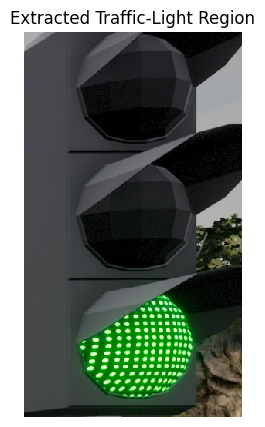

In [ ]:
if not detections:
    raise ValueError(
        "No traffic light detected. Run Cell 3 with another image "
        "and verify detection before continuing."
    )

best_detection = max(detections, key=lambda item: item["score"])
cropped_image = best_detection["crop"]

print("Detected crop shape:", cropped_image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(cropped_image, interpolation="nearest")
plt.title("Extracted Traffic-Light Region")
plt.axis("off")
plt.show()

2×2 grayscale pixel values:
 [[50. 44.]
 [71. 64.]]

Normalized pixel values:
 [[0.19607843 0.17254902]
 [0.2784314  0.2509804 ]]
Normalized shape: (2, 2)


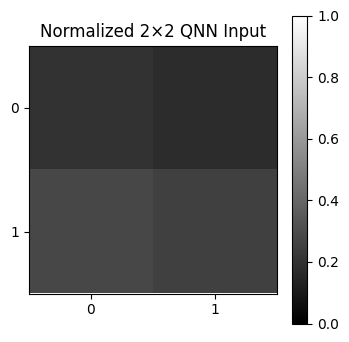

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

crop_pil = Image.fromarray(cropped_image)

resized_image = crop_pil.resize(
    (2, 2),
    Image.Resampling.LANCZOS
).convert("L")

pixel_values = np.asarray(resized_image, dtype=np.float32)

# Normalize pixel values from [0, 255] to [0, 1]
normalized_pixels = pixel_values / 255.0

print("2×2 grayscale pixel values:\n", pixel_values)
print("\nNormalized pixel values:\n", normalized_pixels)
print("Normalized shape:", normalized_pixels.shape)

plt.figure(figsize=(4, 4))
plt.imshow(
    normalized_pixels,
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
plt.title("Normalized 2×2 QNN Input")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.colorbar()
plt.show()

In [ ]:
# Four pixels -> four angles -> four qubits
theta = (normalized_pixels.flatten() * np.pi).astype(np.float32)

print("Angle-encoded values:")
print(theta)
print("Number of encoded angles:", len(theta))

Angle-encoded values:
[0.61599857 0.54207873 0.874718   0.7884782 ]
Number of encoded angles: 4


In [ ]:
assert theta.shape == (4,), "Expected exactly four angle values."
assert np.all(theta >= 0) and np.all(theta <= np.pi)

print("Angle encoding successful.")
print("Ready for the 4-qubit QNN circuit.")

Angle encoding successful.
Ready for the 4-qubit QNN circuit.


In [ ]:

# Install PennyLane if it is not already installed
!pip -q install pennylane

import pennylane as qml
import numpy as np

# -----------------------------------------
# 1. QNN CONFIGURATION
# -----------------------------------------
N_QUBITS = 4
N_LAYERS = 2

dev = qml.device("default.qubit", wires=N_QUBITS)

print("Number of qubits:", N_QUBITS)
print("Number of trainable circuit layers:", N_LAYERS)

# -----------------------------------------
# 2. 4-QUBIT QUANTUM CIRCUIT
# -----------------------------------------
@qml.qnode(dev, interface="autograd")
def qnn_circuit(inputs, weights):

    # Angle encoding: one angle per qubit
    for wire in range(N_QUBITS):
        qml.RX(inputs[wire], wires=wire)

    # Trainable rotations and CNOT entanglement
    for layer in range(N_LAYERS):
        for wire in range(N_QUBITS):
            qml.RY(weights[layer, wire], wires=wire)

        # Entangle neighbouring qubits
        for wire in range(N_QUBITS - 1):
            qml.CNOT(wires=[wire, wire + 1])

        # Connect the last qubit to the first
        qml.CNOT(wires=[N_QUBITS - 1, 0])

    # Measurement: expectation value of Pauli Z
    return tuple(
        qml.expval(qml.PauliZ(wires=wire))
        for wire in range(N_QUBITS)
    )

# -----------------------------------------
# 3. INITIALIZE TRAINABLE PARAMETERS
# -----------------------------------------
np.random.seed(42)

weights = qml.numpy.array(
    np.random.uniform(
        low=-0.1,
        high=0.1,
        size=(N_LAYERS, N_QUBITS)
    ),
    requires_grad=True
)

# -----------------------------------------
# 4. TEST THE CIRCUIT USING YOUR ENCODED IMAGE
# -----------------------------------------
# 'theta' should contain the four angles from your
# successful angle-encoding cell.

theta = np.asarray(theta, dtype=np.float64).reshape(-1)

if theta.shape != (N_QUBITS,):
    raise ValueError(
        f"Expected 4 encoded angles, but received shape {theta.shape}"
    )

qnn_output = qnn_circuit(theta, weights)

print("\nQNN circuit output:")
print(np.array(qnn_output, dtype=float))

print("\nCircuit structure:")
print(qml.draw(qnn_circuit)(theta, weights))


Number of qubits: 4
Number of trainable circuit layers: 2

QNN circuit output:
[0.43749073 0.32701987 0.55392589 0.47502032]

Circuit structure:
0: ──RX(0.62)──RY(-0.03)─╭●───────╭X──RY(-0.07)─╭●───────╭X─┤  <Z>
1: ──RX(0.54)──RY(0.09)──╰X─╭●────│───RY(-0.07)─╰X─╭●────│──┤  <Z>
2: ──RX(0.87)──RY(0.05)─────╰X─╭●─│───RY(-0.09)────╰X─╭●─│──┤  <Z>
3: ──RX(0.79)──RY(0.02)────────╰X─╰●──RY(0.07)────────╰X─╰●─┤  <Z>


In [ ]:

# ============================================================
# CELL: PREPROCESS ALL CARLA IMAGES FOR 4-QUBIT QNN
# ============================================================

import numpy as np
from pathlib import Path
from PIL import Image
import pennylane as qml

# Use the CARLA_ROOT variable defined in your earlier cell
CARLA_ROOT = Path(CARLA_ROOT)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# These class names are read from the dataset folders
SPLITS = ["train", "val"]

X_train_list, y_train_list = [], []
X_val_list, y_val_list = [], []

# Check dataset structure
for split in SPLITS:
    split_path = CARLA_ROOT / split
    if not split_path.exists():
        raise FileNotFoundError(f"Missing dataset folder: {split_path}")

    print(f"\n{split.upper()} classes:")
    print(sorted(p.name for p in split_path.iterdir() if p.is_dir()))

# Create a consistent label mapping across both splits
class_names = sorted({
    folder.name
    for split in SPLITS
    for folder in (CARLA_ROOT / split).iterdir()
    if folder.is_dir()
})

class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

print("\nClass mapping:", class_to_idx)

def preprocess_carla_image(image_path):
    """Return four angle-encoded grayscale pixel features."""
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = image.resize((2, 2), Image.Resampling.LANCZOS)
        image = image.convert("L")
        pixels = np.asarray(image, dtype=np.float32)

    normalized = pixels / 255.0
    angles = normalized.reshape(4) * np.pi
    return angles.astype(np.float32)

# Process every readable image while retaining its split and label
for split in SPLITS:
    split_path = CARLA_ROOT / split
    X_list = X_train_list if split == "train" else X_val_list
    y_list = y_train_list if split == "train" else y_val_list

    for class_folder in sorted(split_path.iterdir()):
        if not class_folder.is_dir():
            continue

        label = class_to_idx[class_folder.name]
        files = [
            p for p in class_folder.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        successful = 0
        for image_path in files:
            try:
                angles = preprocess_carla_image(image_path)
                X_list.append(angles)
                y_list.append(label)
                successful += 1
            except Exception as error:
                print(f"Skipped {image_path.name}: {error}")

        print(f"{split}/{class_folder.name}: {successful} images processed")

# Convert lists to arrays
X_train = np.asarray(X_train_list, dtype=np.float32)
y_train = np.asarray(y_train_list, dtype=np.int64)
X_val = np.asarray(X_val_list, dtype=np.float32)
y_val = np.asarray(y_val_list, dtype=np.int64)

print("\n========== CARLA PREPROCESSING SUMMARY ==========")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:  ", X_val.shape)
print("y_val shape:  ", y_val.shape)
print("Number of classes:", len(class_names))
print("Classes:", class_names)

assert X_train.ndim == 2 and X_train.shape[1] == 4
assert X_val.ndim == 2 and X_val.shape[1] == 4
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_train) > 0 and len(X_val) > 0

print("\nCARLA preprocessing completed successfully.")



TRAIN classes:
['back', 'green', 'red', 'yellow']

VAL classes:
['back', 'green', 'red', 'yellow']

Class mapping: {'back': 0, 'green': 1, 'red': 2, 'yellow': 3}
train/back: 517 images processed
train/green: 559 images processed
train/red: 564 images processed
train/yellow: 503 images processed
val/back: 100 images processed
val/green: 100 images processed
val/red: 100 images processed
val/yellow: 83 images processed

========== CARLA PREPROCESSING SUMMARY ==========
X_train shape: (2143, 4)
y_train shape: (2143,)
X_val shape:   (383, 4)
y_val shape:   (383,)
Number of classes: 4
Classes: ['back', 'green', 'red', 'yellow']

CARLA preprocessing completed successfully.


In [ ]:

# ============================================================
# CELL 1: PREPROCESS ALL IMAGES IN BOTH DATASETS
# ============================================================

import numpy as np
from pathlib import Path
from PIL import Image

CARLA_ROOT = Path("/content/datasets/archive(2)/traffic_light_data")
LISA_ROOT = Path("/content/datasets/lisa_extracted/cropped_lisa_1")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def find_split(root, possible_names):
    for name in possible_names:
        path = root / name
        if path.is_dir():
            return path
    raise FileNotFoundError(
        f"Could not find any of {possible_names} inside {root}"
    )

def process_dataset(root, train_names, val_names, dataset_name):
    train_dir = find_split(root, train_names)
    val_dir = find_split(root, val_names)

    def class_folders(split_dir):
        return sorted(
            p for p in split_dir.iterdir()
            if p.is_dir()
        )

    train_folders = class_folders(train_dir)
    val_folders = class_folders(val_dir)

    train_classes = {p.name for p in train_folders}
    val_classes = {p.name for p in val_folders}

    if train_classes != val_classes:
        raise ValueError(
            f"{dataset_name}: train/validation classes differ.\n"
            f"Train: {sorted(train_classes)}\n"
            f"Validation: {sorted(val_classes)}"
        )

    classes = sorted(train_classes)
    class_to_idx = {name: i for i, name in enumerate(classes)}

    def load_split(split_dir):
        features, labels = [], []
        counts = {}

        for folder in sorted(class_folders(split_dir)):
            files = [
                p for p in folder.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            ]

            count = 0
            for path in files:
                try:
                    with Image.open(path) as img:
                        img = img.convert("RGB")
                        img = img.resize(
                            (2, 2), Image.Resampling.LANCZOS
                        )
                        img = img.convert("L")
                        pixels = np.asarray(img, dtype=np.float32)

                    angles = (pixels.reshape(4) / 255.0) * np.pi

                    features.append(angles.astype(np.float32))
                    labels.append(class_to_idx[folder.name])
                    count += 1

                except Exception as exc:
                    print(f"Skipped {path}: {exc}")

            counts[folder.name] = count

        return (
            np.asarray(features, dtype=np.float32),
            np.asarray(labels, dtype=np.int64),
            counts
        )

    X_train, y_train, train_counts = load_split(train_dir)
    X_val, y_val, val_counts = load_split(val_dir)

    if len(X_train) == 0 or len(X_val) == 0:
        raise ValueError(f"{dataset_name}: a split contains no usable images.")

    print(f"\n===== {dataset_name} =====")
    print("Classes:", classes)
    print("Training images by class:", train_counts)
    print("Validation images by class:", val_counts)
    print("X_train:", X_train.shape, "y_train:", y_train.shape)
    print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
    print("Total successfully processed:", len(X_train) + len(X_val))

    return {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "classes": classes,
        "class_to_idx": class_to_idx
    }

carla_data = process_dataset(
    CARLA_ROOT,
    ["train"],
    ["val", "valid", "validation"],
    "CARLA"
)

lisa_data = process_dataset(
    LISA_ROOT,
    ["train_1", "train"],
    ["val_1", "val", "valid", "validation"],
    "Cropped LISA"
)

print("\nBoth datasets have been preprocessed.")



===== CARLA =====
Classes: ['back', 'green', 'red', 'yellow']
Training images by class: {'back': 517, 'green': 559, 'red': 564, 'yellow': 503}
Validation images by class: {'back': 100, 'green': 100, 'red': 100, 'yellow': 83}
X_train: (2143, 4) y_train: (2143,)
X_val:   (383, 4) y_val:   (383,)
Total successfully processed: 2526

===== Cropped LISA =====
Classes: ['go', 'goForward', 'goLeft', 'stop', 'stopLeft', 'warning', 'warningLeft']
Training images by class: {'go': 12840, 'goForward': 184, 'goLeft': 1030, 'stop': 14865, 'stopLeft': 2845, 'warning': 985, 'warningLeft': 48}
Validation images by class: {'go': 1372, 'goForward': 21, 'goLeft': 109, 'stop': 1777, 'stopLeft': 345, 'warning': 108, 'warningLeft': 5}
X_train: (32797, 4) y_train: (32797,)
X_val:   (3737, 4) y_val:   (3737,)
Total successfully processed: 36534

Both datasets have been preprocessed.


In [ ]:

from google.colab import drive
drive.mount("/content/drive", force_remount=True)


Mounted at /content/drive


In [ ]:

import os

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Checkpoint folder ready:", CHECKPOINT_DIR)


Checkpoint folder ready: /content/drive/MyDrive/QNN_Checkpoints


In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn
import pennylane as qml
from torch.utils.data import TensorDataset, DataLoader

# Training settings
N_QUBITS = 4
N_LAYERS = 2
N_EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 0.001

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Quantum circuit
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qnn_circuit(inputs, weights):
    for i in range(N_QUBITS):
        qml.RX(inputs[i], wires=i)

    for layer in range(N_LAYERS):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i], wires=i)

        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        qml.CNOT(wires=[N_QUBITS - 1, 0])

    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]


# Hybrid QNN model
class HybridQNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.q_weights = nn.Parameter(
            0.01 * torch.randn(N_LAYERS, N_QUBITS, dtype=torch.float32)
        )
        self.classifier = nn.Linear(N_QUBITS, num_classes).float()

    def forward(self, x):
        outputs = []
        for sample in x:
            result = qnn_circuit(sample.float(), self.q_weights)
            outputs.append(torch.stack(list(result)).float())
        return self.classifier(torch.stack(outputs).float())


# Train and save every 10 epochs
def train_dataset(data, dataset_name):
    X_train = torch.tensor(data["X_train"], dtype=torch.float32)
    y_train = torch.tensor(data["y_train"], dtype=torch.long)
    X_val = torch.tensor(data["X_val"], dtype=torch.float32)
    y_val = torch.tensor(data["y_val"], dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=BATCH_SIZE,
        shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(X_val, y_val),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    model = HybridQNN(len(data["classes"]))
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )
    criterion = nn.CrossEntropyLoss()

    history = {
        "loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{dataset_name.replace(' ', '_')}_checkpoint.pth"
    )

    print(f"\n===== {dataset_name} Training =====")

    for epoch in range(N_EPOCHS):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)

        train_acc = 100 * correct / total
        train_loss = total_loss / total

        model.eval()
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                logits = model(xb)
                val_correct += (logits.argmax(1) == yb).sum().item()
                val_total += len(yb)

        val_acc = 100 * val_correct / val_total

        history["loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch+1}/{N_EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Train: {train_acc:.2f}% | "
            f"Validation: {val_acc:.2f}%"
        )

        # Automatically save after epochs 10 and 20
        if (epoch + 1) % 10 == 0:
            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
                "classes": data["classes"]
            }, checkpoint_path)

            print(f"Checkpoint saved: epoch {epoch+1}")

    return model, history


In [ ]:

!pip -q install pennylane scikit-learn

import os
import numpy as np
import torch
import torch.nn as nn
import pennylane as qml
from torch.utils.data import TensorDataset, DataLoader

# Configuration
N_QUBITS = 4
N_LAYERS = 2
N_EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 0.001

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

torch.manual_seed(42)
np.random.seed(42)

dev = qml.device("default.qubit", wires=N_QUBITS)


# Quantum circuit
@qml.qnode(dev, interface="torch", diff_method="backprop")
def qnn_circuit(inputs, weights):
    # Angle encoding
    for i in range(N_QUBITS):
        qml.RX(inputs[i], wires=i)

    # Trainable rotations and entanglement
    for layer in range(N_LAYERS):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i], wires=i)

        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        qml.CNOT(wires=[N_QUBITS - 1, 0])

    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]


# QNN-only model: no classical linear layer
class QNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.q_weights = nn.Parameter(
            0.01 * torch.randn(N_LAYERS, N_QUBITS)
        )

        # Trainable measurement-to-class coefficients
        # These are used to produce class scores without nn.Linear.
        self.measurement_weights = nn.Parameter(
            0.01 * torch.randn(num_classes, N_QUBITS)
        )
        self.class_bias = nn.Parameter(torch.zeros(num_classes))

    def forward(self, x):
        outputs = []

        for sample in x:
            result = qnn_circuit(sample.float(), self.q_weights)
            outputs.append(torch.stack(list(result)).float())

        measurements = torch.stack(outputs).float()

        # Class scores derived directly from quantum measurements
        scores = measurements @ self.measurement_weights.T
        scores = scores + self.class_bias

        return scores


def train_qnn(data, dataset_name):
    X_train = torch.tensor(data["X_train"], dtype=torch.float32)
    y_train = torch.tensor(data["y_train"], dtype=torch.long)
    X_val = torch.tensor(data["X_val"], dtype=torch.float32)
    y_val = torch.tensor(data["y_val"], dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(X_val, y_val),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    model = QNN(len(data["classes"]))
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )
    criterion = nn.CrossEntropyLoss()

    history = {
        "loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{dataset_name.replace(' ', '_')}_QNN_checkpoint.pth"
    )

    print(f"\n===== {dataset_name}: QNN Training =====")

    for epoch in range(N_EPOCHS):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for xb, yb in train_loader:
            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)

        train_loss = total_loss / total
        train_acc = 100 * correct / total

        model.eval()
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                logits = model(xb)
                val_correct += (
                    logits.argmax(dim=1) == yb
                ).sum().item()
                val_total += len(yb)

        val_acc = 100 * val_correct / val_total

        history["loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1:02d}/{N_EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Train accuracy: {train_acc:.2f}% | "
            f"Validation accuracy: {val_acc:.2f}%"
        )

        # Save checkpoints after epochs 10 and 20
        if (epoch + 1) % 10 == 0:
            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
                "classes": data["classes"]
            }, checkpoint_path)

            print(f"Checkpoint saved at epoch {epoch + 1}")

    return model, history


# Train both datasets independently
carla_model, carla_history = train_qnn(
    carla_data, "CARLA"
)

lisa_model, lisa_history = train_qnn(
    lisa_data, "Cropped LISA"
)



===== CARLA: QNN Training =====
Epoch 01/20 | Loss: 1.3799 | Train accuracy: 27.53% | Validation accuracy: 34.20%
Epoch 02/20 | Loss: 1.3604 | Train accuracy: 44.33% | Validation accuracy: 37.60%
Epoch 03/20 | Loss: 1.3388 | Train accuracy: 50.35% | Validation accuracy: 39.16%
Epoch 04/20 | Loss: 1.3165 | Train accuracy: 49.88% | Validation accuracy: 38.38%
Epoch 05/20 | Loss: 1.2952 | Train accuracy: 49.51% | Validation accuracy: 38.90%
Epoch 06/20 | Loss: 1.2757 | Train accuracy: 49.23% | Validation accuracy: 38.64%
Epoch 07/20 | Loss: 1.2581 | Train accuracy: 49.23% | Validation accuracy: 39.43%
Epoch 08/20 | Loss: 1.2424 | Train accuracy: 48.81% | Validation accuracy: 39.95%
Epoch 09/20 | Loss: 1.2279 | Train accuracy: 49.98% | Validation accuracy: 39.69%
Epoch 10/20 | Loss: 1.2146 | Train accuracy: 51.14% | Validation accuracy: 40.21%
Checkpoint saved at epoch 10
Epoch 11/20 | Loss: 1.2025 | Train accuracy: 51.47% | Validation accuracy: 40.73%
Epoch 12/20 | Loss: 1.1911 | Train a

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"

print("Checkpoint folder exists:", os.path.exists(CHECKPOINT_DIR))
print("Saved files:", os.listdir(CHECKPOINT_DIR))

Mounted at /content/drive
Checkpoint folder exists: True
Saved files: ['Cropped_LISA_QNN_checkpoint.pth', 'CARLA_QNN_checkpoint.pth']


In [ ]:
import torch
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"

for filename in [
    "CARLA_QNN_checkpoint.pth",
    "Cropped_LISA_QNN_checkpoint.pth"
]:
    path = os.path.join(CHECKPOINT_DIR, filename)

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print(f"\n{filename}")
    print("Saved epoch:", checkpoint.get("epoch", "Unknown"))
    print("Saved classes:", checkpoint.get("classes", "Not available"))
    print("Saved history keys:", list(checkpoint.get("history", {}).keys())
          if isinstance(checkpoint.get("history"), dict)
          else type(checkpoint.get("history")).__name__)


CARLA_QNN_checkpoint.pth
Saved epoch: 20
Saved classes: ['back', 'green', 'red', 'yellow']
Saved history keys: ['loss', 'train_accuracy', 'val_accuracy']

Cropped_LISA_QNN_checkpoint.pth
Saved epoch: 20
Saved classes: ['go', 'goForward', 'goLeft', 'stop', 'stopLeft', 'warning', 'warningLeft']
Saved history keys: ['loss', 'train_accuracy', 'val_accuracy']


In [ ]:
import torch
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"

for filename in [
    "CARLA_QNN_checkpoint.pth",
    "Cropped_LISA_QNN_checkpoint.pth"
]:
    path = os.path.join(CHECKPOINT_DIR, filename)
    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )

    history = checkpoint["history"]

    print(f"\n===== {filename} =====")
    print("Checkpoint epoch:", checkpoint["epoch"])

    for key, values in history.items():
        print(f"{key}: {len(values)} recorded epochs")
        print("Last recorded value:", values[-1] if values else "No values")



===== CARLA_QNN_checkpoint.pth =====
Checkpoint epoch: 20
loss: 20 recorded epochs
Last recorded value: 1.1235601189422428
train_accuracy: 20 recorded epochs
Last recorded value: 53.33644423705086
val_accuracy: 20 recorded epochs
Last recorded value: 43.60313315926893

===== Cropped_LISA_QNN_checkpoint.pth =====
Checkpoint epoch: 20
loss: 20 recorded epochs
Last recorded value: 0.6863554885144837
train_accuracy: 20 recorded epochs
Last recorded value: 75.8179101747111
val_accuracy: 20 recorded epochs
Last recorded value: 79.39523682097939


========== QNN HYPERPARAMETERS AND RESULTS ==========


,Dataset,Epochs,Learning Rate,Optimizer,Batch Size,Training Accuracy (%),Validation Accuracy (%),Final Training Loss
0,CARLA,20,0.001,Adam,32,53.3364,43.6031,1.1236
1,Cropped LISA,20,0.001,Adam,32,75.8179,79.3952,0.6864


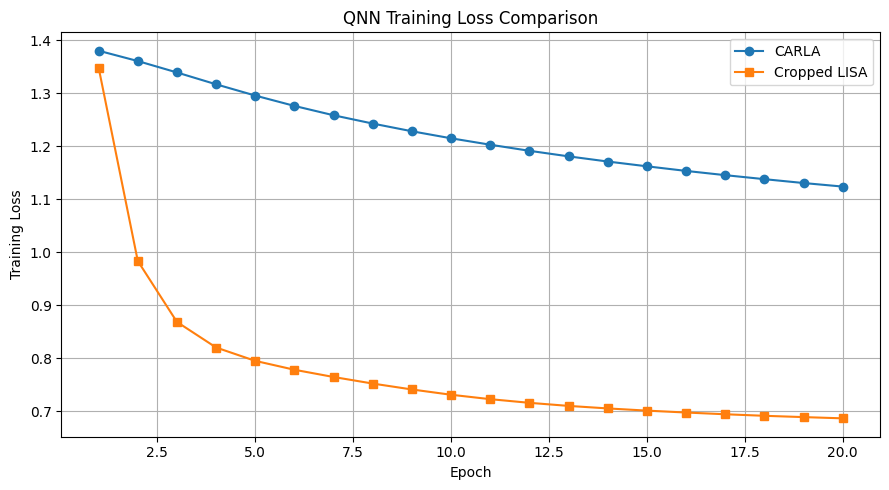

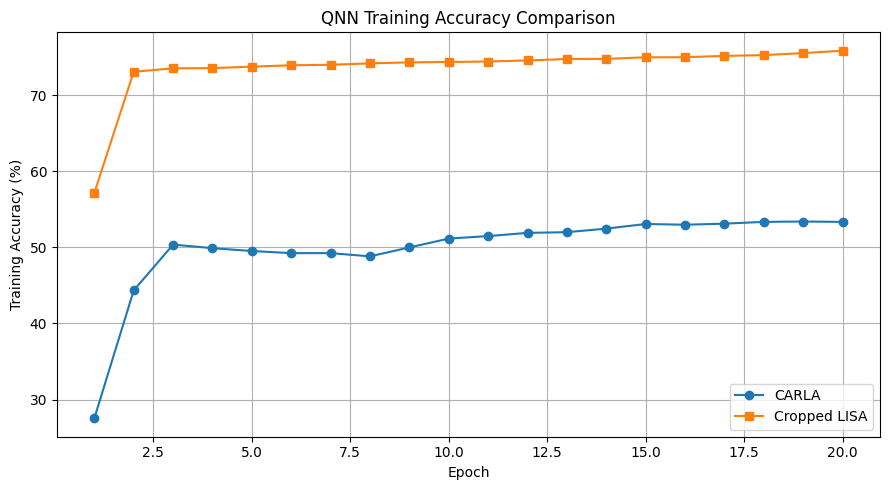

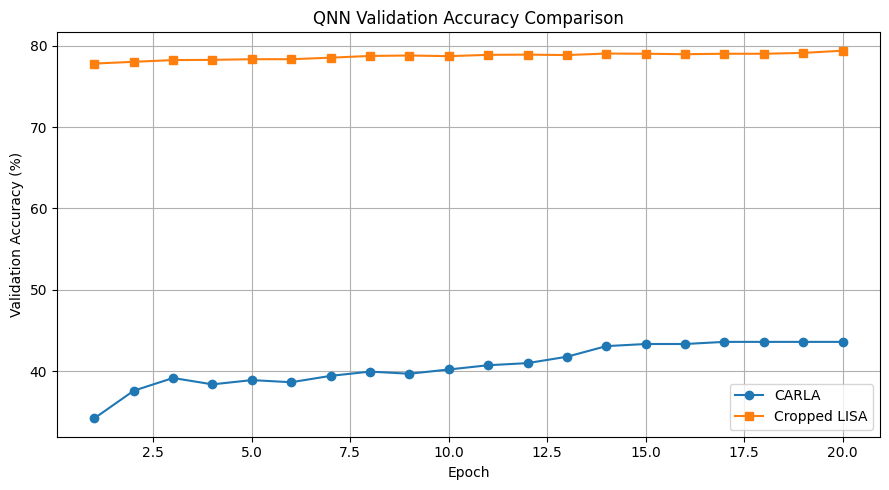

Results table saved to /content/QNN_results_comparison.csv


In [ ]:

# ============================================================
# QNN RESULTS: CARLA AND CROPPED LISA
# Load saved histories, print tables, and plot graphs
# No retraining required
# ============================================================

import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"

# ------------------------------------------------------------
# 1. Load saved checkpoints
# ------------------------------------------------------------
carla_path = os.path.join(CHECKPOINT_DIR, "CARLA_QNN_checkpoint.pth")
lisa_path = os.path.join(CHECKPOINT_DIR, "Cropped_LISA_QNN_checkpoint.pth")

carla_ckpt = torch.load(
    carla_path, map_location="cpu", weights_only=False
)
lisa_ckpt = torch.load(
    lisa_path, map_location="cpu", weights_only=False
)

carla_history = carla_ckpt["history"]
lisa_history = lisa_ckpt["history"]

# ------------------------------------------------------------
# 2. Hyperparameter and final-results comparison table
# ------------------------------------------------------------
results_table = pd.DataFrame([
    {
        "Dataset": "CARLA",
        "Epochs": carla_ckpt["epoch"],
        "Learning Rate": 0.001,
        "Optimizer": "Adam",
        "Batch Size": 32,
        "Training Accuracy (%)": carla_history["train_accuracy"][-1],
        "Validation Accuracy (%)": carla_history["val_accuracy"][-1],
        "Final Training Loss": carla_history["loss"][-1]
    },
    {
        "Dataset": "Cropped LISA",
        "Epochs": lisa_ckpt["epoch"],
        "Learning Rate": 0.001,
        "Optimizer": "Adam",
        "Batch Size": 32,
        "Training Accuracy (%)": lisa_history["train_accuracy"][-1],
        "Validation Accuracy (%)": lisa_history["val_accuracy"][-1],
        "Final Training Loss": lisa_history["loss"][-1]
    }
])

print("========== QNN HYPERPARAMETERS AND RESULTS ==========")
display(results_table.round(4))

# ------------------------------------------------------------
# 3. Plot training loss
# ------------------------------------------------------------
epochs_carla = range(1, len(carla_history["loss"]) + 1)
epochs_lisa = range(1, len(lisa_history["loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_carla, carla_history["loss"], marker="o",
         label="CARLA")
plt.plot(epochs_lisa, lisa_history["loss"], marker="s",
         label="Cropped LISA")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("QNN Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Plot training accuracy
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(carla_history["train_accuracy"]) + 1),
         carla_history["train_accuracy"], marker="o",
         label="CARLA")
plt.plot(range(1, len(lisa_history["train_accuracy"]) + 1),
         lisa_history["train_accuracy"], marker="s",
         label="Cropped LISA")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("QNN Training Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Plot validation accuracy
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(carla_history["val_accuracy"]) + 1),
         carla_history["val_accuracy"], marker="o",
         label="CARLA")
plt.plot(range(1, len(lisa_history["val_accuracy"]) + 1),
         lisa_history["val_accuracy"], marker="s",
         label="Cropped LISA")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("QNN Validation Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Save tables as CSV files
# ------------------------------------------------------------
results_table.to_csv(
    "/content/QNN_results_comparison.csv", index=False
)

print("Results table saved to /content/QNN_results_comparison.csv")


In [ ]:

# ============================================================
# QNN EVALUATION: CARLA AND CROPPED LISA
# Requires: carla_data, lisa_data, QNN, qnn_circuit
# Does not train the models again
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

CHECKPOINT_DIR = "/content/drive/MyDrive/QNN_Checkpoints"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use the same architecture settings as the original model
N_QUBITS = 4
N_LAYERS = 2


def evaluate_saved_qnn(data, dataset_name, checkpoint_filename):
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, checkpoint_filename
    )

    checkpoint = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=False
    )

    classes = checkpoint["classes"]

    # Recreate the original model architecture.
    # Adjust constructor arguments only if your original QNN
    # class uses a different signature.
    model = QNN(
        num_classes=len(classes),
        n_qubits=N_QUBITS,
        n_layers=N_LAYERS
    ).to(DEVICE)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    # Accept the existing train/validation arrays from preprocessing.
    X_val = torch.as_tensor(data["X_val"], dtype=torch.float32)
    y_val = torch.as_tensor(data["y_val"], dtype=torch.long)

    predictions = []

    with torch.no_grad():
        for start in range(0, len(X_val), 32):
            batch = X_val[start:start + 32].to(DEVICE)
            outputs = model(batch)
            predictions.extend(outputs.argmax(dim=1).cpu().tolist())

    y_true = y_val.cpu().numpy()
    y_pred = np.array(predictions)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    print(f"\n{'=' * 20} {dataset_name} {'=' * 20}")
    print(f"Checkpoint epoch: {checkpoint['epoch']}")
    print(f"Validation samples: {len(y_true)}")
    print(f"Accuracy:  {accuracy * 100:.2f}%")
    print(f"Precision (macro): {precision:.4f}")
    print(f"Recall (macro):    {recall:.4f}")
    print(f"F1-score (macro):  {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0,
        digits=4
    ))

    cm = confusion_matrix(
        y_true, y_pred, labels=list(range(len(classes)))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=classes
    )
    fig, ax = plt.subplots(figsize=(9, 7))
    display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
    ax.set_title(f"{dataset_name} - QNN Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return {
        "Dataset": dataset_name,
        "Epochs": checkpoint["epoch"],
        "Accuracy (%)": accuracy * 100,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-score": f1
    }


# Evaluate both saved checkpoints
carla_metrics = evaluate_saved_qnn(
    carla_data,
    "CARLA",
    "CARLA_QNN_checkpoint.pth"
)

lisa_metrics = evaluate_saved_qnn(
    lisa_data,
    "Cropped LISA",
    "Cropped_LISA_QNN_checkpoint.pth"
)

# Print the comparison table
metrics_table = pd.DataFrame([carla_metrics, lisa_metrics])

print("\n========== EVALUATION METRICS COMPARISON ==========")
print(metrics_table.round(4).to_string(index=False))

metrics_table.to_csv(
    "/content/QNN_evaluation_metrics.csv", index=False
)
print("\nSaved: /content/QNN_evaluation_metrics.csv")


NameError: name 'carla_data' is not defined